# Foundations of Generative AI (ICT4403), Assignment 2
## Autoregressive word-level text generation: SimpleRNN vs Bidirectional RNN vs LSTM vs GRU

**Dataset:** *The Rámáyan of Válmíki*, English verse translation by Ralph T. H. Griffith (Project Gutenberg #24869), about 2.3 MB of text.
**Task:** predict the next word from the previous `SEQ_LEN` words, then generate text one word at a time.

How this notebook is organised:

1. Setup and config
2. Dataset: load, describe, preprocess, build input/target sequences (Task i)
3. Build and train the four models under identical settings (Task i)
4. Quantitative evaluation: loss, perplexity, accuracy, training time (Task ii)
5. Text generation with the same seeds, three sampling temperatures (Task iii)
6. Qualitative and quantitative analysis of the generated text (Tasks ii and iii)
7. Summary tables for the README

Everything written to `results/` is meant to be committed to GitHub along with this notebook.

## 1. Setup and config

In [1]:
# On Colab / Kaggle, uncomment the next line if TensorFlow is missing
# !pip install -q tensorflow numpy pandas matplotlib

import os, re, time, json, collections, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

try:
    from IPython.display import display
except ImportError:
    display = print

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0 | Keras: 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# ---------------- Config (same for all four models) ----------------
QUICK_TEST = False        # True = tiny run just to check the code works

SEED        = 42
DATA_URL    = "https://www.gutenberg.org/ebooks/24869.txt.utf-8"   # Project Gutenberg, plain text UTF-8
DATA_PATH   = "data/ramayana_griffith.txt"
BLOCK_SIZE  = 1000        # tokens per block, used for the train/val/test split

SEQ_LEN     = 10          # context window: previous 10 tokens -> next token
MIN_FREQ    = 3           # words seen fewer than 3 times in TRAIN become <unk>
EMB_DIM     = 128
UNITS       = 256         # recurrent units (per direction for the BiRNN)
DROPOUT     = 0.3
BATCH_SIZE  = 256
MAX_EPOCHS  = 20
PATIENCE    = 2           # early stopping on validation loss
LR          = 1e-3

MODEL_NAMES = ["SimpleRNN", "BiRNN", "LSTM", "GRU"]
TEMPERATURES = [0.5, 1.0, 1.5]
GEN_WORDS = 50            # words generated per sample
SAMPLES_PER_SETTING = 3   # samples per (model, seed, temperature) used for the metrics
SAVE_MODELS = True

# Seed texts (must have at least SEQ_LEN tokens). Same seeds for every model.
SEEDS = {
    "Seed A": "then rama spoke to lakshman and to sita, and thus he said",
    "Seed B": "the sage replied: hear me, o king,\nand i will tell the tale",
    "Seed C": "ravan the demon king, with eyes of flame, drew near",
}

if QUICK_TEST:
    MAX_EPOCHS, UNITS, EMB_DIM, SAMPLES_PER_SETTING, GEN_WORDS = 1, 64, 32, 1, 15

for d in ("data", "results", "models"):
    os.makedirs(d, exist_ok=True)
keras.utils.set_random_seed(SEED)

## 2. Dataset: load, describe, preprocess (Task i)

The Rámáyan of Válmíki is one of the two great Sanskrit epics of India. This version is Ralph T. H. Griffith's English verse translation (1870 to 1874),
available on Project Gutenberg (public domain). It is written in rhymed couplets, has a fixed cast (Ráma, Sítá, Lakshman, Rávan, Hanumán),
and reuses a lot of epic phrases. That makes it easy to judge contextual consistency, line structure and repetition in the generated text.

Source: https://www.gutenberg.org/ebooks/24869

In [3]:
def download(url, path):
    # Gutenberg can reject Python's default user agent, so send a normal one
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (FGAI assignment)"})
    with urllib.request.urlopen(req, timeout=60) as r, open(path, "wb") as f:
        f.write(r.read())

def clean_gutenberg(text):
    # keep only the book itself: drop the licence header and footer
    text = text.lstrip("\ufeff")
    m = re.search(r"\*\*\*\s*START OF (?:THE|THIS) PROJECT GUTENBERG EBOOK[^\n]*\n", text, flags=re.I)
    if m:
        text = text[m.end():]
    m = re.search(r"\*\*\*\s*END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK", text, flags=re.I)
    if m:
        text = text[:m.start()]
    return text

if not os.path.exists(DATA_PATH):
    download(DATA_URL, DATA_PATH)   # if this fails, download the .txt by hand and save it as DATA_PATH

raw = clean_gutenberg(open(DATA_PATH, encoding="utf-8").read())
if QUICK_TEST:
    raw = raw[:150_000]

print(f"Characters       : {len(raw):,}")
print(f"Lines            : {raw.count(chr(10)):,}")
print(f"Unique characters: {len(set(raw))}")
print("\n--- first 400 characters ---")
print(raw[:400])

Characters       : 2,264,303
Lines            : 67,456
Unique characters: 189

--- first 400 characters ---





                         *The RÁMÁYAN of VÁLMÍKI*

                     *Translated into English Verse*

                                   *by*

                        Ralph T. H. Griffith, M.A.

                     Principal of the Benares College

                          London: Trübner & Co.

                      Benares: E. J. Lazarus and Co.

                                1870-18


### Preprocessing

Steps, in order:

1. Cut the Project Gutenberg licence header and footer (done above with the START / END markers).
2. Clean the text: strip accents (`Ráma` -> `rama`), remove page markers like `[pg 001]`, remove digits (they are footnote numbers glued to words, like `song,3`), lowercase, collapse blank lines.
3. Split into tokens: words (apostrophes kept, like `Ráma's`), the punctuation marks `. , ! ? ; :`, and a special `<nl>` token for line breaks.
   Keeping punctuation and `<nl>` lets the model learn the verse layout (short lines, couplets).
4. Cut the token stream into blocks of `BLOCK_SIZE` tokens, shuffle the blocks, and give 90% of them to train, 5% to validation, 5% to test.
   Windows are built inside each block, so no test window overlaps with training text.
   (Randomly splitting individual windows would leak because neighbouring windows overlap, and splitting in order would test only on the end of the epic, which has different characters and places.)
5. Build the vocabulary from the **train split only**. Words seen fewer than `MIN_FREQ` times become `<unk>`.
   `<unk>` is never allowed to be sampled during generation.

Total tokens          : 526,523
Unique tokens         : 16,597
Tokens seen only once : 6,498 (39.2% of unique tokens)
Avg tokens per line   : 8.7

Most common tokens:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
token,<nl>,",",the,.,and,of,to,his,with,in,a,:,he,that,i
count,60414,41775,25821,19881,17284,10372,8507,6479,6393,6274,4535,4196,3918,2920,2873


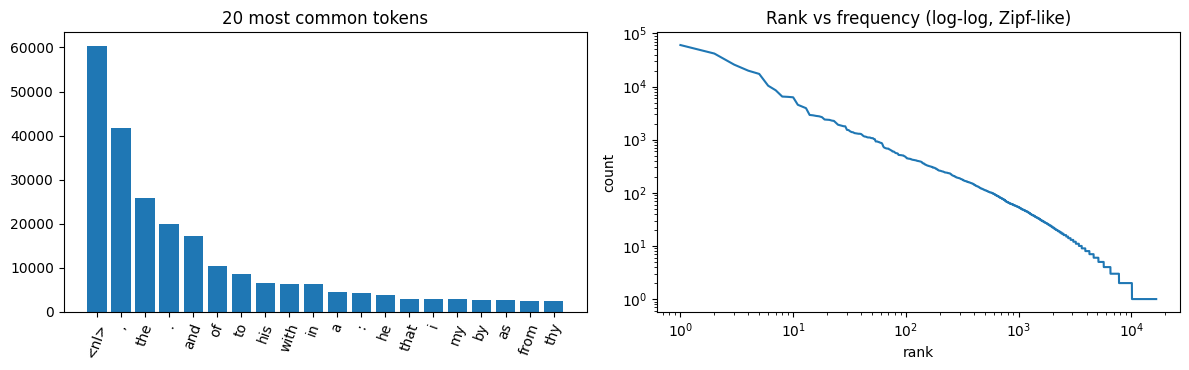

In [4]:
import unicodedata

TOKEN_RE = re.compile(r"\n|[a-z]+(?:'[a-z]+)?|[.,!?;:]")

def normalize(text):
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = unicodedata.normalize("NFKD", text)
    text = "".join(c for c in text if not unicodedata.combining(c))   # Ráma -> Rama
    text = re.sub(r"\[pg\s*\d+\]", " ", text, flags=re.I)                # page markers
    text = re.sub(r"\d+", " ", text)                                    # footnote / page numbers
    return text.lower()

def tokenize(text):
    text = re.sub(r"\s*\n\s*", "\n", normalize(text))
    return ["<nl>" if t == "\n" else t for t in TOKEN_RE.findall(text)]

tokens = tokenize(raw)
cnt_all = collections.Counter(tokens)
hapax = sum(1 for c in cnt_all.values() if c == 1)

print(f"Total tokens          : {len(tokens):,}")
print(f"Unique tokens         : {len(cnt_all):,}")
print(f"Tokens seen only once : {hapax:,} ({hapax/len(cnt_all):.1%} of unique tokens)")
print(f"Avg tokens per line   : {len(tokens)/max(tokens.count('<nl>'),1):.1f}")
print("\nMost common tokens:")
display(pd.DataFrame(cnt_all.most_common(15), columns=["token", "count"]).T)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
top = cnt_all.most_common(20)
ax[0].bar([w for w, _ in top], [c for _, c in top])
ax[0].set_title("20 most common tokens"); ax[0].tick_params(axis="x", rotation=70)
freqs = sorted(cnt_all.values(), reverse=True)
ax[1].loglog(range(1, len(freqs) + 1), freqs)
ax[1].set_title("Rank vs frequency (log-log, Zipf-like)")
ax[1].set_xlabel("rank"); ax[1].set_ylabel("count")
plt.tight_layout(); plt.savefig("results/dataset_stats.png", dpi=150); plt.show()

In [5]:
blocks = [tokens[i:i + BLOCK_SIZE] for i in range(0, len(tokens), BLOCK_SIZE)]
blocks = [b for b in blocks if len(b) > SEQ_LEN]
order = np.random.default_rng(SEED).permutation(len(blocks))
n_hold = max(1, round(0.05 * len(blocks)))
test_blocks  = [blocks[i] for i in order[:n_hold]]
val_blocks   = [blocks[i] for i in order[n_hold:2 * n_hold]]
train_blocks = [blocks[i] for i in order[2 * n_hold:]]
print(f"Blocks: train={len(train_blocks)}  val={len(val_blocks)}  test={len(test_blocks)}")

train_tok = [t for b in train_blocks for t in b]
val_tok   = [t for b in val_blocks for t in b]
test_tok  = [t for b in test_blocks for t in b]

cnt_train = collections.Counter(train_tok)
itos = ["<unk>"] + [w for w, c in cnt_train.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
UNK_ID, VOCAB_SIZE = 0, len(itos)

def encode(toks):
    return np.array([stoi.get(t, UNK_ID) for t in toks], dtype=np.int32)

train_bl_ids = [encode(b) for b in train_blocks]
val_bl_ids   = [encode(b) for b in val_blocks]
test_bl_ids  = [encode(b) for b in test_blocks]
train_ids, val_ids, test_ids = (np.concatenate(x) for x in (train_bl_ids, val_bl_ids, test_bl_ids))

print(f"Split sizes (tokens): train={len(train_ids):,}  val={len(val_ids):,}  test={len(test_ids):,}")
print(f"Vocabulary size     : {VOCAB_SIZE:,} (including <unk>)")
print(f"<unk> share of train: {(train_ids == UNK_ID).mean():.2%}")
print(f"<unk> share of test : {(test_ids == UNK_ID).mean():.2%}")

Blocks: train=475  val=26  test=26
Split sizes (tokens): train=474,523  val=26,000  test=26,000
Vocabulary size     : 7,361 (including <unk>)
<unk> share of train: 2.25%
<unk> share of test : 3.62%


### Input and target sequences (autoregressive setup)

A sliding window moves over the token ids with stride 1.
For a window of `SEQ_LEN + 1` ids, the first `SEQ_LEN` are the input and the last one is the target (the next word).

```
tokens : w1 w2 w3 w4 w5 w6 ...
sample1: [w1 w2 w3 w4 w5]  ->  w6
sample2: [w2 w3 w4 w5 w6]  ->  w7
```

In [6]:
def make_xy(block_ids, L):
    xs, ys = [], []
    for ids in block_ids:                      # windows never cross a block boundary
        w = np.lib.stride_tricks.sliding_window_view(ids, L + 1)
        xs.append(w[:, :-1]); ys.append(w[:, -1])
    return np.concatenate(xs), np.concatenate(ys)

X_train, y_train = make_xy(train_bl_ids, SEQ_LEN)
X_val,   y_val   = make_xy(val_bl_ids,   SEQ_LEN)
X_test,  y_test  = make_xy(test_bl_ids,  SEQ_LEN)
print("X_train", X_train.shape, "y_train", y_train.shape)
print("X_val  ", X_val.shape,   "y_val  ", y_val.shape)
print("X_test ", X_test.shape,  "y_test ", y_test.shape)

print("\nExample sample:")
print("  input :", " ".join(itos[i] for i in X_train[100]))
print("  target:", itos[y_train[100]])

# Baseline for reference: a model that ignores the context and always uses word frequencies
uni = np.bincount(train_ids, minlength=VOCAB_SIZE).astype("float64")
uni /= uni.sum()
base_loss = -np.log(uni[y_test]).mean()
base_acc = (y_test == uni.argmax()).mean()
print(f"\nUnigram baseline on test: perplexity={np.exp(base_loss):.1f}, top-1 accuracy={base_acc:.3f}")

X_train (469773, 10) y_train (469773,)
X_val   (25740, 10) y_val   (25740,)
X_test  (25740, 10) y_test  (25740,)

Example sample:
  input : . <nl> bound by its root it must remain ;
  target: <nl>

Unigram baseline on test: perplexity=333.0, top-1 accuracy=0.117


## 3. The four models (Task i)

All four share the same skeleton so the comparison is fair. Only the recurrent layer changes:

`Embedding(128)` -> **recurrent layer (256 units)** -> `Dropout(0.3)` -> `Dense(vocab, softmax)`

| Model | Recurrent layer |
|---|---|
| SimpleRNN | `SimpleRNN(256)` |
| BiRNN | `Bidirectional(SimpleRNN(256))` reads the 10-word context forward and backward, outputs are joined (512 features) |
| LSTM | `LSTM(256)` |
| GRU | `GRU(256)` |

The BiRNN only looks at the **previous** words in the window (in both directions). It never sees the word being predicted, so it is still a valid autoregressive model.
Because it has two RNNs, it has more parameters than the others at the same `UNITS`. That is reported in the results table.

Same for all: Adam (lr 1e-3, gradient clipping 1.0), batch size 256, up to 20 epochs, early stopping on validation loss (patience 2, best weights restored), same random seed.

In [7]:
def build_model(kind):
    keras.utils.set_random_seed(SEED)          # same init seed for every model
    inp = keras.Input(shape=(SEQ_LEN,), dtype="int32")
    x = layers.Embedding(VOCAB_SIZE, EMB_DIM)(inp)
    if kind == "SimpleRNN":
        x = layers.SimpleRNN(UNITS)(x)
    elif kind == "BiRNN":
        x = layers.Bidirectional(layers.SimpleRNN(UNITS))(x)
    elif kind == "LSTM":
        x = layers.LSTM(UNITS)(x)
    elif kind == "GRU":
        x = layers.GRU(UNITS)(x)
    else:
        raise ValueError(kind)
    x = layers.Dropout(DROPOUT)(x)
    out = layers.Dense(VOCAB_SIZE, activation="softmax")(x)
    model = keras.Model(inp, out, name=kind)
    model.compile(
        optimizer=keras.optimizers.Adam(LR, clipnorm=1.0),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(5, name="top5_acc")],
    )
    return model

models = {name: build_model(name) for name in MODEL_NAMES}
models["LSTM"].summary()
print(pd.DataFrame({"parameters": {n: m.count_params() for n, m in models.items()}}))

I0000 00:00:1792154365.044024      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792154365.048109      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 10, 128)        │       942,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7361)           │     1,891,777 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,228,225 (12.31 MB)

 Trainable params: 3,228,225 (12.31 MB)

 Non-trainable params: 0 (0.00 B)

           parameters
SimpleRNN     2932545
BiRNN         4915521
LSTM          3228225
GRU           3130433


### Training
First a throwaway warm-up fit, so one-time start-up cost (GPU init, graph tracing) does not get charged to the first model's training time.

In [8]:
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._t = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self._t)

# warm-up (not reported)
_w = build_model("GRU")
_w.fit(X_train[:BATCH_SIZE * 4], y_train[:BATCH_SIZE * 4], epochs=1, batch_size=BATCH_SIZE, verbose=0)
del _w

histories, rows = {}, []
for name in MODEL_NAMES:
    print(f"\n=========== Training {name} ===========")
    m = models[name]
    timer = EpochTimer()
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=MAX_EPOCHS,
              batch_size=BATCH_SIZE, callbacks=[es, timer], verbose=2)
    histories[name] = h.history
    pd.DataFrame(h.history).to_csv(f"results/history_{name}.csv", index=False)

    best = int(np.argmin(h.history["val_loss"]))
    test = m.evaluate(X_test, y_test, batch_size=1024, verbose=0, return_dict=True)
    rows.append({
        "model": name,
        "params": m.count_params(),
        "epochs_run": len(timer.times),
        "best_epoch": best + 1,
        "train_time_s": sum(timer.times),
        "sec_per_epoch": float(np.mean(timer.times)),
        "train_loss": h.history["loss"][best],
        "val_loss": h.history["val_loss"][best],
        "test_loss": test["loss"],
        "test_ppl": float(np.exp(test["loss"])),
        "test_acc": test["accuracy"],
        "test_top5": test["top5_acc"],
    })
    if SAVE_MODELS:
        m.save(f"models/{name}.keras")


=========== Training SimpleRNN ===========
Epoch 1/20


I0000 00:00:1792154376.329122     124 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1836/1836 - 16s - 9ms/step - accuracy: 0.2015 - loss: 5.2089 - top5_acc: 0.3784 - val_accuracy: 0.2356 - val_loss: 4.6887 - val_top5_acc: 0.4194
Epoch 2/20
1836/1836 - 8s - 5ms/step - accuracy: 0.2398 - loss: 4.6035 - top5_acc: 0.4240 - val_accuracy: 0.2538 - val_loss: 4.4736 - val_top5_acc: 0.4427
Epoch 3/20
1836/1836 - 9s - 5ms/step - accuracy: 0.2544 - loss: 4.3700 - top5_acc: 0.4419 - val_accuracy: 0.2565 - val_loss: 4.3954 - val_top5_acc: 0.4523
Epoch 4/20
1836/1836 - 8s - 5ms/step - accuracy: 0.2633 - loss: 4.2197 - top5_acc: 0.4537 - val_accuracy: 0.2593 - val_loss: 4.3633 - val_top5_acc: 0.4584
Epoch 5/20
1836/1836 - 9s - 5ms/step - accuracy: 0.2703 - loss: 4.1010 - top5_acc: 0.4634 - val_accuracy: 0.2592 - val_loss: 4.3565 - val_top5_acc: 0.4608
Epoch 6/20
1836/1836 - 9s - 5ms/step - accuracy: 0.2765 - loss: 4.0043 - top5_acc: 0.4722 - val_accuracy: 0.2629 - val_loss: 4.3546 - val_top5_acc: 0.4628
Epoch 7/20
1836/1836 - 9s - 5ms/step - accuracy: 0.2822 - loss: 3.9187 - top5_ac

## 4. Quantitative comparison (Task ii)

- **Loss**: cross-entropy of the next-word prediction on the test split (lower is better).
- **Perplexity**: `exp(loss)`. Roughly "how many words the model is torn between at each step". Lower is better.
- **Accuracy**: top-1 (exact next word) and top-5 (true word is among the 5 most likely).
- **Training time**: total seconds spent in training epochs, plus seconds per epoch (because early stopping makes epoch counts differ).

Note: `train_loss` is measured with dropout switched on, so it is naturally a bit higher than it would be at inference time.

,model,params,epochs_run,best_epoch,train_time_s,sec_per_epoch,train_loss,val_loss,test_loss,test_ppl,test_acc,test_top5
0,SimpleRNN,2932545,8,6,76.306,9.538,4.004,4.355,4.240,69.399,0.270,0.468
1,BiRNN,4915521,5,3,73.049,14.610,4.280,4.470,4.371,79.138,0.260,0.452
2,LSTM,3228225,9,7,174.889,19.432,3.853,4.219,4.100,60.340,0.283,0.485
3,GRU,3130433,8,6,149.053,18.632,3.785,4.153,4.039,56.789,0.289,0.490


Unigram baseline: test perplexity=333.0, top-1 accuracy=0.117


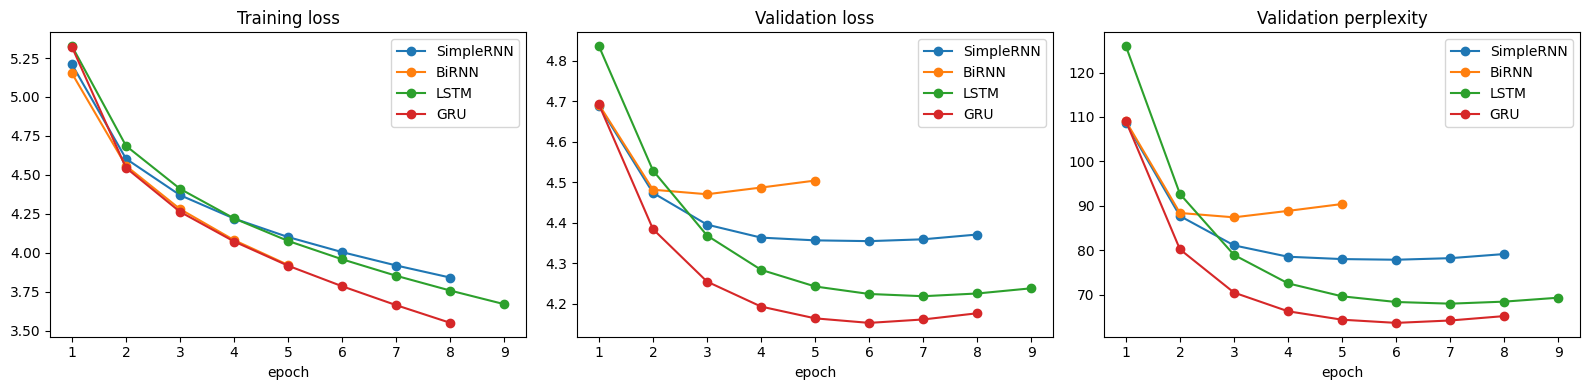

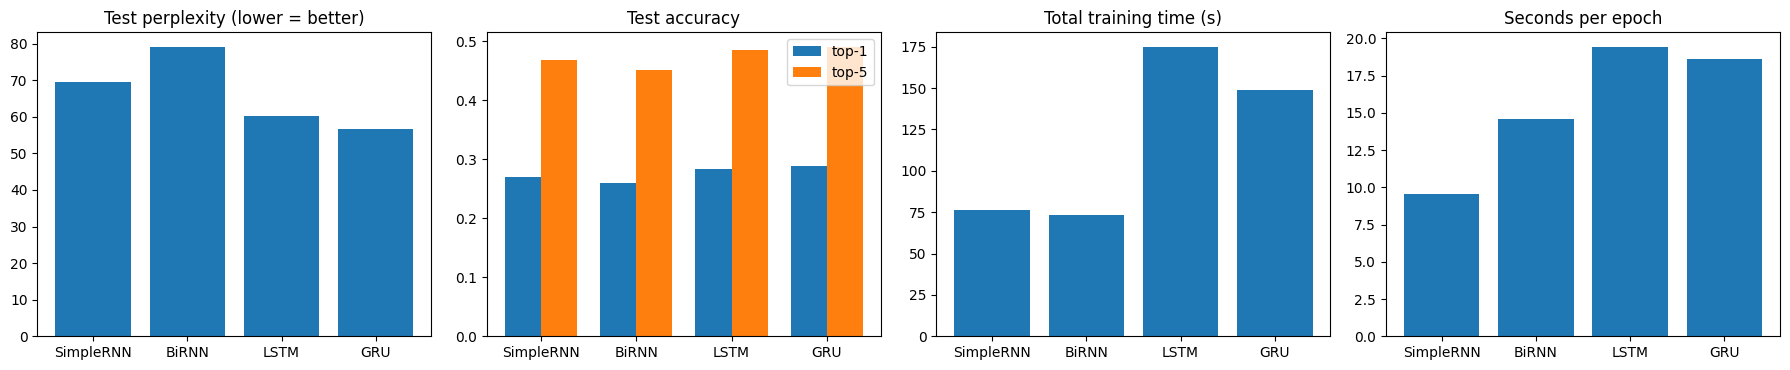

In [9]:
results = pd.DataFrame(rows)
results.to_csv("results/metrics.csv", index=False)
display(results.round(3))
print(f"Unigram baseline: test perplexity={np.exp(base_loss):.1f}, top-1 accuracy={base_acc:.3f}")

# --- training curves ---
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, h in histories.items():
    ep = range(1, len(h["loss"]) + 1)
    ax[0].plot(ep, h["loss"], marker="o", label=name)
    ax[1].plot(ep, h["val_loss"], marker="o", label=name)
    ax[2].plot(ep, np.exp(h["val_loss"]), marker="o", label=name)
for a, t in zip(ax, ["Training loss", "Validation loss", "Validation perplexity"]):
    a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig("results/training_curves.png", dpi=150); plt.show()

# --- bar charts ---
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
ax[0].bar(results["model"], results["test_ppl"]); ax[0].set_title("Test perplexity (lower = better)")
w = 0.38; xs = np.arange(len(results))
ax[1].bar(xs - w/2, results["test_acc"], w, label="top-1")
ax[1].bar(xs + w/2, results["test_top5"], w, label="top-5")
ax[1].set_xticks(xs); ax[1].set_xticklabels(results["model"]); ax[1].set_title("Test accuracy"); ax[1].legend()
ax[2].bar(results["model"], results["train_time_s"]); ax[2].set_title("Total training time (s)")
ax[3].bar(results["model"], results["sec_per_epoch"]); ax[3].set_title("Seconds per epoch")
plt.tight_layout(); plt.savefig("results/model_comparison.png", dpi=150); plt.show()

## 5. Text generation and temperature (Task iii)

Generation loop: take the last 10 tokens, get the probability of every word, pick one, append it, slide the window, repeat.

**Temperature** rescales the probabilities before sampling: `p_i  ~  exp(log(p_i) / T)`.

- `T < 1` sharpens the distribution (safer, more repetitive, more predictable)
- `T = 1` samples from the model's own distribution
- `T > 1` flattens it (more variety, more chances of nonsense)

Every model gets the same three seeds and the same three temperatures (0.5, 1.0, 1.5). `<unk>` is blocked from being sampled.

In [10]:
def seed_to_ids(seed_text):
    toks = tokenize(seed_text)
    assert len(toks) >= SEQ_LEN, f"seed needs at least {SEQ_LEN} tokens, got {len(toks)}"
    return [stoi.get(t, UNK_ID) for t in toks[-SEQ_LEN:]]

def sample_next(probs, temperature, rng):
    logp = np.log(np.clip(probs.astype("float64"), 1e-12, None)) / temperature
    p = np.exp(logp - logp.max())
    p[UNK_ID] = 0.0
    p /= p.sum()
    return int(rng.choice(len(p), p=p))

def generate(model, seed_text, temperature, n_words=GEN_WORDS, rng=None):
    rng = rng or np.random.default_rng(SEED)
    window = seed_to_ids(seed_text)
    out = []
    for _ in range(n_words):
        x = np.array([window[-SEQ_LEN:]], dtype="int32")
        probs = np.asarray(model(x, training=False))[0]
        nxt = sample_next(probs, temperature, rng)
        out.append(nxt); window.append(nxt)
    return [itos[i] for i in out]

def detok(tokens):
    lines, cur = [], []
    for t in tokens:
        if t == "<nl>":
            lines.append(" ".join(cur)); cur = []
        else:
            cur.append(t)
    lines.append(" ".join(cur))
    return "\n".join(re.sub(r" ([.,!?;:])", r"\1", l).strip() for l in lines)

# quick sanity check
print(detok(generate(models["LSTM"], SEEDS["Seed A"], 1.0)))

: and thence not a heeds him death
as is soft youth but come and won,
but mournful heart itself once more,
the giant chiefs whose cloth was spread.
and lakshman, only rama duly:
shafts raised his hands a joy


### Automatic text-quality measures

Reading samples is essential, but these numbers help compare many samples. They are **proxies**, not a replacement for reading.

| Measure | What it tells us | Better direction |
|---|---|---|
| `distinct1`, `distinct2` | unique words / bigrams divided by total (diversity) | higher |
| `rep_trigram` | share of trigrams that repeat an earlier trigram in the same text (repetition, looping) | lower |
| `bigram_valid` | share of generated word pairs that also occur in the training text (local fluency, a rough coherence proxy) | higher |
| `copy4` | share of generated 4-word chunks copied exactly from the training text (memorisation) | lower |

Only the generated words are scored (the seed is excluded). Punctuation and `<nl>` count as tokens.

In [11]:
def ngrams(t, n):
    return list(zip(*[t[i:] for i in range(n)]))

train_bigrams  = set(g for b in train_blocks for g in ngrams(b, 2))
train_fourgram = set(g for b in train_blocks for g in ngrams(b, 4))

def distinct_n(t, n):
    g = ngrams(t, n)
    return len(set(g)) / len(g) if g else np.nan

def text_metrics(gen):
    g2, g4 = ngrams(gen, 2), ngrams(gen, 4)
    return {
        "distinct1": distinct_n(gen, 1),
        "distinct2": distinct_n(gen, 2),
        "rep_trigram": 1 - distinct_n(gen, 3),
        "bigram_valid": float(np.mean([b in train_bigrams for b in g2])) if g2 else np.nan,
        "copy4": float(np.mean([g in train_fourgram for g in g4])) if g4 else np.nan,
    }

gen_rows = []
for name in MODEL_NAMES:
    for si, (sname, stext) in enumerate(SEEDS.items()):
        for T in TEMPERATURES:
            for k in range(SAMPLES_PER_SETTING):
                rng = np.random.default_rng(SEED + 100 * si + 10 * k + int(T * 10))
                gen = generate(models[name], stext, T, rng=rng)
                gen_rows.append({"model": name, "seed": sname, "temperature": T, "sample": k,
                                 "text": detok(gen), **text_metrics(gen)})

gen_df = pd.DataFrame(gen_rows)
gen_df.to_csv("results/generated_samples.csv", index=False)
print(len(gen_df), "generated samples saved")

108 generated samples saved


### Generated text (first sample of each setting)

In [12]:
lines = ["# Generated samples\n"]
for sname, stext in SEEDS.items():
    for T in TEMPERATURES:
        head = f"{sname} | temperature {T}"
        print("=" * 90); print(head); print("seed:", repr(stext)); print("=" * 90)
        lines += [f"## {head}", f"Seed: `{stext!r}`", ""]
        for name in MODEL_NAMES:
            row = gen_df[(gen_df.model == name) & (gen_df.seed == sname) &
                         (gen_df.temperature == T) & (gen_df["sample"] == 0)].iloc[0]
            print(f"\n[{name}]\n{row.text}")
            lines += [f"**{name}**", "```", row.text, "```", ""]
        print()
open("results/generated_samples.md", "w", encoding="utf-8").write("\n".join(lines))

Seed A | temperature 0.5
seed: 'then rama spoke to lakshman and to sita, and thus he said'

[SimpleRNN]
to go.
so the great sage, the best of men,
and, for a friend and all thy life.
here, when he saw the royal street.
the royal monarch, lord of men,
the king of men,

[BiRNN]
,
and the king's touch of women.
with noble hands the royal sway
with comfort and his words to him.
but well the host of raghu's son,
and by the saints that follows learn
the vanar of the fight to him

[LSTM]
to the
king to the gods.
the modern power, and the same part of the
poem, and the celebrated section follows. the poet is
he who pervades the poem, and and are always
in the earth, as the great

[GRU]
to be
, according to the vow of the people.
one who is the destroyer of the world.
the asvins or a lion of the four regions of the asvamedha; and
the siddhas or rudra, and the gods, and the


Seed A | temperature 1.0
seed: 'then rama spoke to lakshman and to sita, and thus he said'

[SimpleRNN]
in joy to
i insta

9124

## 6. Temperature analysis (Task iii)

Averages over all seeds and all samples for each model and temperature.

,model,temperature,distinct1,distinct2,rep_trigram,bigram_valid,copy4
0,BiRNN,0.5,0.560,0.855,0.032,0.941,0.340
1,BiRNN,1.0,0.722,0.955,0.000,0.737,0.102
2,BiRNN,1.5,0.813,0.977,0.000,0.535,0.019
3,GRU,0.5,0.513,0.787,0.102,0.973,0.553
4,GRU,1.0,0.736,0.955,0.000,0.771,0.121
5,GRU,1.5,0.820,0.984,0.000,0.522,0.028
6,LSTM,0.5,0.571,0.832,0.060,0.948,0.461
7,LSTM,1.0,0.747,0.966,0.000,0.782,0.076
8,LSTM,1.5,0.804,0.973,0.000,0.605,0.031
9,SimpleRNN,0.5,0.484,0.748,0.153,0.984,0.520


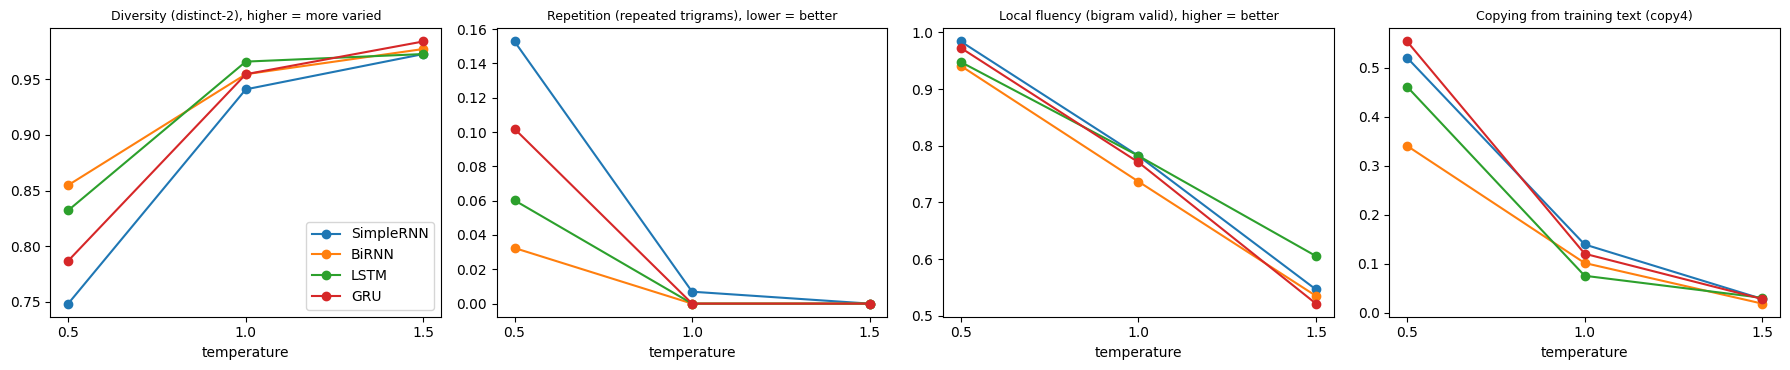

In [13]:
metric_cols = ["distinct1", "distinct2", "rep_trigram", "bigram_valid", "copy4"]
temp_df = gen_df.groupby(["model", "temperature"])[metric_cols].mean().reset_index()
temp_df.to_csv("results/temperature_metrics.csv", index=False)
display(temp_df.round(3))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, col, title in zip(ax, ["distinct2", "rep_trigram", "bigram_valid", "copy4"],
                         ["Diversity (distinct-2), higher = more varied",
                          "Repetition (repeated trigrams), lower = better",
                          "Local fluency (bigram valid), higher = better",
                          "Copying from training text (copy4)"]):
    for name in MODEL_NAMES:
        d = temp_df[temp_df.model == name]
        a.plot(d["temperature"], d[col], marker="o", label=name)
    a.set_title(title, fontsize=9); a.set_xlabel("temperature"); a.set_xticks(TEMPERATURES)
ax[0].legend()
plt.tight_layout(); plt.savefig("results/temperature_analysis.png", dpi=150); plt.show()

## 7. Summary tables for the README

This cell ranks the models and writes `results/results_tables.md`. Paste those tables into the README, then write the analysis and conclusion in your own words after reading the samples.

In [14]:
def md_table(df, fmt="{:.3f}"):
    cols = list(df.columns)
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(fmt.format(v) if isinstance(v, float) else str(v) for v in r) + " |")
    return "\n".join(out)

main = results[["model", "params", "epochs_run", "best_epoch", "train_time_s", "sec_per_epoch",
                "test_loss", "test_ppl", "test_acc", "test_top5"]].copy()
main["train_time_s"] = main["train_time_s"].round(1)
main["sec_per_epoch"] = main["sec_per_epoch"].round(1)

at1 = temp_df[temp_df.temperature == 1.0].set_index("model")[["distinct2", "rep_trigram", "bigram_valid", "copy4"]]
score = results.set_index("model")[["test_ppl", "test_acc", "train_time_s"]].join(at1)
ranks = pd.DataFrame({
    "ppl_rank (low best)": score["test_ppl"].rank(),
    "acc_rank (high best)": score["test_acc"].rank(ascending=False),
    "time_rank (low best)": score["train_time_s"].rank(),
    "bigram_valid@1.0 rank": score["bigram_valid"].rank(ascending=False),
    "repetition@1.0 rank (low best)": score["rep_trigram"].rank(),
}).reset_index()

with open("results/results_tables.md", "w", encoding="utf-8") as f:
    f.write("### Training and test results\n\n" + md_table(main) + "\n\n")
    f.write(f"Unigram baseline (ignores context): perplexity {np.exp(base_loss):.1f}, top-1 accuracy {base_acc:.3f}\n\n")
    f.write("### Text quality by temperature (mean over seeds and samples)\n\n" + md_table(temp_df) + "\n\n")
    f.write("### Rankings (1 = best)\n\n" + md_table(ranks, "{:g}") + "\n")

display(main); display(ranks)
print("Best test perplexity:", results.sort_values("test_ppl").iloc[0]["model"])
print("Saved: results/results_tables.md")

,model,params,epochs_run,best_epoch,train_time_s,sec_per_epoch,test_loss,test_ppl,test_acc,test_top5
0,SimpleRNN,2932545,8,6,76.3,9.5,4.239871,69.398867,0.270435,0.468493
1,BiRNN,4915521,5,3,73.0,14.6,4.371191,79.137831,0.259674,0.451865
2,LSTM,3228225,9,7,174.9,19.4,4.099989,60.339620,0.282556,0.484732
3,GRU,3130433,8,6,149.1,18.6,4.039337,56.788688,0.288967,0.490365


,model,ppl_rank (low best),acc_rank (high best),time_rank (low best),bigram_valid@1.0 rank,repetition@1.0 rank (low best)
0,SimpleRNN,3.0,3.0,2.0,1.5,4.0
1,BiRNN,4.0,4.0,1.0,4.0,2.0
2,LSTM,2.0,2.0,4.0,1.5,2.0
3,GRU,1.0,1.0,3.0,3.0,2.0


Best test perplexity: GRU
Saved: results/results_tables.md


### Next steps

1. Read `results/generated_samples.md` and rate each model by hand for coherence, diversity, contextual consistency, and repetition.
2. Fill in the README sections using `results/results_tables.md` and the plots in `results/`.
3. Commit the notebook, `README.md`, `requirements.txt`, and the `results/` folder to GitHub.